In [ ]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, concatenate
from google.colab import drive

# 1. Drive'ı Bağla
drive.mount('/content/drive')

# Daha önce belirlediğimiz ayrıştırılmış verilerin bulunduğu tam yol
DATA_PATH = '/content/drive/MyDrive/Bitirme_Tezi_BraTS/Ayrilmis_Veriler/'

# 2. Segmentasyon için Veri Yükleyici (Data Generator) Altyapısı
def load_brats_data_for_segmentation(veri_yolu):
    """
    Karakterizasyon DEĞİL, segmentasyon için veriyi hazırlar.
    Giriş (X): [T1, T1ce, T2, FLAIR] (4 Kanallı)
    Çıkış (Y): Maske (1 Kanallı)
    """
    print(f"Veriler segmentasyon hedefine göre şu yoldan yükleniyor:\n{veri_yolu}")

    # Burası .npy dosyalarını okuyacak kısım
    # Örnek: X_train = np.load(os.path.join(veri_yolu, 'X_train.npy'))
    #        Y_train = np.load(os.path.join(veri_yolu, 'Y_train.npy'))

    print("Beklenen X (Giriş) Boyutu: (Örnek_Sayısı, 240, 240, 4)")
    print("Beklenen Y (Maske) Boyutu: (Örnek_Sayısı, 240, 240, 1)")

    # return X_train, Y_train
    pass

# 3. U-Net Mimarisi (Segmentasyon Hedefli)
def build_unet_segmentation(input_shape=(240, 240, 4)):
    inputs = Input(input_shape)

    # Encoder
    c1 = Conv2D(64, 3, activation='relu', padding='same')(inputs)
    p1 = MaxPooling2D()(c1)

    c2 = Conv2D(128, 3, activation='relu', padding='same')(p1)
    p2 = MaxPooling2D()(c2)

    # Bottleneck
    b = Conv2D(256, 3, activation='relu', padding='same')(p2)

    # Decoder
    u1 = UpSampling2D()(b)
    concat1 = concatenate([u1, c2])
    c3 = Conv2D(128, 3, activation='relu', padding='same')(concat1)

    u2 = UpSampling2D()(c3)
    concat2 = concatenate([u2, c1])
    c4 = Conv2D(64, 3, activation='relu', padding='same')(concat2)

    # Çıkış Katmanı: Piksel tabanlı maskeleme (0 ile 1 arası değerler)
    outputs = Conv2D(1, 1, activation='sigmoid')(c4)

    model = Model(inputs=inputs, outputs=outputs)
    return model

# Modeli oluştur ve derle
model = build_unet_segmentation()
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

print("U-Net Segmentasyon Modeli Başarıyla Oluşturuldu!")

Mounted at /content/drive
U-Net Segmentasyon Modeli Başarıyla Oluşturuldu!


In [ ]:
import os

# Kontrol etmek istediğimiz yol
kontrol_yolu = '/content/drive/MyDrive/Bitirme_Tezi_BraTS/Ayrilmis_Veriler/'

if os.path.exists(kontrol_yolu):
    print("✅ Klasör başarıyla bulundu! İçindeki gerçek dosyalar şunlar:\n")
    dosyalar = os.listdir(kontrol_yolu)
    for dosya in dosyalar:
        print(f"- {dosya}")
else:
    print("❌ HATA: 'Ayrilmis_Veriler' diye bir klasör bu yolda yok!")
    print("\nBir üst klasörün (Bitirme_Tezi_BraTS) içindekileri kontrol ediyorum:")
    ust_yol = '/content/drive/MyDrive/Bitirme_Tezi_BraTS/'
    if os.path.exists(ust_yol):
        for dosya in os.listdir(ust_yol):
            print(f"- {dosya}")
    else:
        print("❌ HATA: 'Bitirme_Tezi_BraTS' klasörü de Drive ana dizininde bulunamadı.")

✅ Klasör başarıyla bulundu! İçindeki gerçek dosyalar şunlar:

- train
- val
- test


In [ ]:
import os

train_yolu = '/content/drive/MyDrive/Bitirme_Tezi_BraTS/Ayrilmis_Veriler/train/'

if os.path.exists(train_yolu):
    print("Train klasörünün içindeki yapı (ilk 10 öğe):\n")
    dosyalar = os.listdir(train_yolu)
    for dosya in dosyalar[:10]:
        print(f"- {dosya}")
else:
    print("Train klasörüne ulaşılamadı.")

Train klasörünün içindeki yapı (ilk 10 öğe):

- BraTS-GLI-01370-000
- BraTS-GLI-01199-000
- BraTS-GLI-00641-000
- BraTS-GLI-00455-000
- BraTS-GLI-01011-000
- BraTS-GLI-00654-001
- BraTS-GLI-00124-000
- BraTS-GLI-00444-000
- BraTS-GLI-00336-000
- BraTS-GLI-00685-000


In [ ]:
import os

ornek_hasta_yolu = '/content/drive/MyDrive/Bitirme_Tezi_BraTS/Ayrilmis_Veriler/train/BraTS-GLI-01370-000'

if os.path.exists(ornek_hasta_yolu):
    print("Bu hastanın içindeki dosyalar:\n")
    for dosya in os.listdir(ornek_hasta_yolu):
        print(f"- {dosya}")
else:
    print("Klasör bulunamadı.")

Bu hastanın içindeki dosyalar:

- BraTS-GLI-01370-000-t2w.nii.gz
- BraTS-GLI-01370-000-seg.nii.gz
- BraTS-GLI-01370-000-t1n.nii.gz
- BraTS-GLI-01370-000-t1c.nii.gz
- BraTS-GLI-01370-000-t2f.nii.gz


In [ ]:
import os
import numpy as np
import tensorflow as tf
import nibabel as nib
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# Eğer Colab'de yüklü değilse nibabel'i indir
!pip install nibabel

# 1. 3D Medikal Veriden 2D Kesit Çıkaran Veri Üretici (Data Generator)
class BraTSDataGenerator(tf.keras.utils.Sequence):
    def __init__(self, data_path, batch_size=8, dim=(240, 240), n_channels=4, slice_idx=75):
        self.data_path = data_path
        self.batch_size = batch_size
        self.dim = dim
        self.n_channels = n_channels
        self.slice_idx = slice_idx # 3D beyin hacminden 75. kesiti (genelde tümörün en net olduğu orta alan) alıyoruz

        # Sadece klasör olanları listeye al (gizli dosyaları atla)
        self.case_list = [d for d in os.listdir(data_path) if os.path.isdir(os.path.join(data_path, d))]

    def __len__(self):
        return int(np.floor(len(self.case_list) / self.batch_size))

    def __getitem__(self, index):
        batch_cases = self.case_list[index * self.batch_size:(index + 1) * self.batch_size]

        X = np.empty((self.batch_size, *self.dim, self.n_channels))
        y = np.empty((self.batch_size, *self.dim, 1))

        for i, case in enumerate(batch_cases):
            case_path = os.path.join(self.data_path, case)

            # 4 sekansı ve maskeyi oku
            t1n = nib.load(os.path.join(case_path, f'{case}-t1n.nii.gz')).get_fdata()
            t1c = nib.load(os.path.join(case_path, f'{case}-t1c.nii.gz')).get_fdata()
            t2w = nib.load(os.path.join(case_path, f'{case}-t2w.nii.gz')).get_fdata()
            t2f = nib.load(os.path.join(case_path, f'{case}-t2f.nii.gz')).get_fdata()
            seg = nib.load(os.path.join(case_path, f'{case}-seg.nii.gz')).get_fdata()

            # Belirlenen kesiti (slice) alıp kanalları birleştir
            X[i, :, :, 0] = t1n[:, :, self.slice_idx]
            X[i, :, :, 1] = t1c[:, :, self.slice_idx]
            X[i, :, :, 2] = t2w[:, :, self.slice_idx]
            X[i, :, :, 3] = t2f[:, :, self.slice_idx]

            # Maskeyi al (BraTS'ta 1,2,4 gibi etiketler vardır. Hepsini 1 yaparak tekil tümör maskesine çeviriyoruz)
            mask_slice = seg[:, :, self.slice_idx]
            mask_slice[mask_slice > 0] = 1
            y[i, :, :, 0] = mask_slice

        return X, y

# 2. Generator'ları Tanımla (Yolları doğru klasörlere bağlıyoruz)
train_yolu = '/content/drive/MyDrive/Bitirme_Tezi_BraTS/Ayrilmis_Veriler/train/'
val_yolu = '/content/drive/MyDrive/Bitirme_Tezi_BraTS/Ayrilmis_Veriler/val/'

# Batch size 8 idealdir, RAM'i şişirmez
train_gen = BraTSDataGenerator(train_yolu, batch_size=8)
val_gen = BraTSDataGenerator(val_yolu, batch_size=8)

print("Veri üreticileri hazırlandı. Eğitim ortamı kuruluyor...")

# 3. Model Kayıt ve Koruma Noktaları (Callbacks)
kayit_yolu = '/content/drive/MyDrive/Bitirme_Tezi_BraTS/unet_segmentasyon_en_iyi.keras'

checkpoint = ModelCheckpoint(
    filepath=kayit_yolu,
    monitor='val_loss',
    verbose=1,
    save_best_only=True,
    mode='min'
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    verbose=1,
    restore_best_weights=True
)

# 4. Eğitimi Başlat
print("Segmentasyon eğitimi başlatılıyor! Arkana yaslan ve val_loss değerinin düşüşünü izle.")

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=50,
    callbacks=[checkpoint, early_stopping]
)

print("Eğitim tamamlandı! Model ağırlıkları Drive'a kaydedildi.")

Veri üreticileri hazırlandı. Eğitim ortamı kuruluyor...
Segmentasyon eğitimi başlatılıyor! Arkana yaslan ve val_loss değerinin düşüşünü izle.


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 32s/step - accuracy: 0.8795 - loss: 24.1787 
Epoch 1: val_loss improved from None to 3.11083, saving model to /content/drive/MyDrive/Bitirme_Tezi_BraTS/unet_segmentasyon_en_iyi.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Bitirme_Tezi_BraTS/unet_segmentasyon_en_iyi.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 507s 40s/step - accuracy: 0.9001 - loss: 15.3355 - val_accuracy: 0.9680 - val_loss: 3.1108
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 25s/step - accuracy: 0.9715 - loss: 2.7993 
Epoch 2: val_loss improved from 3.11083 to 1.01317, saving model to /content/drive/MyDrive/Bitirme_Tezi_BraTS/unet_segmentasyon_en_iyi.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Bitirme_Tezi_BraTS/unet_segmentasyon_en_iyi.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 324s 27s/step - accuracy: 0.9576 - loss: 2.0234 - val_accuracy: 0.8974 - val_loss: 1.0132
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 24s/step - accuracy: 0.9624 - loss: 0.5954 
Epoch 3: val_l

In [ ]:
import tensorflow as tf
import tensorflow.keras.backend as K

# 1. Eğitim sırasında jürinin istediği Dice Skorunu anlık görmek için metrik fonksiyonu
def dice_coef(y_true, y_pred, smooth=1e-6):
    # Veriyi düzleştirip örtüşmeyi hesapla
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

# 2. Esas Kahraman: Dice Loss (Kayıp Fonksiyonu)
# Modelin amacı her zaman 'loss' değerini sıfıra indirmektir.
# Eğer 1'den Dice Skorunu çıkarırsak, model Dice'ı %100 yapmaya mecbur kalır.
def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

# 3. Modeli bu yeni akıllı kayıp fonksiyonuyla tekrar derle
# Not: Modeli baştan inşa eden (build_unet_segmentation) hücreyi çalıştırdıktan HEMEN SONRA bunu çalıştır.
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), # Öğrenme oranını biraz kıstık, daha ince öğrensin
    loss=dice_loss,           # Artık Binary Crossentropy çöpe gitti, sahnede Dice Loss var
    metrics=[dice_coef, 'accuracy'] # Eğitim akarken ekranda Dice skorunu canlı göreceğiz
)

print("🧠 U-Net modeli 'Dice Loss' zekasıyla başarıyla derlendi! Sınıf dengesizliği tuzağı iptal edildi.")

🧠 U-Net modeli 'Dice Loss' zekasıyla başarıyla derlendi! Sınıf dengesizliği tuzağı iptal edildi.


In [ ]:
import os
import numpy as np
import tensorflow as tf
import nibabel as nib
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# 1. Veri Üreticiyi (Generator) Tekrar Tanımla (Hafızadan silindiği için)
class BraTSDataGenerator(tf.keras.utils.Sequence):
    def __init__(self, data_path, batch_size=8, dim=(240, 240), n_channels=4, slice_idx=75):
        self.data_path = data_path
        self.batch_size = batch_size
        self.dim = dim
        self.n_channels = n_channels
        self.slice_idx = slice_idx
        self.case_list = [d for d in os.listdir(data_path) if os.path.isdir(os.path.join(data_path, d))]

    def __len__(self):
        return int(np.floor(len(self.case_list) / self.batch_size))

    def __getitem__(self, index):
        batch_cases = self.case_list[index * self.batch_size:(index + 1) * self.batch_size]
        X = np.empty((self.batch_size, *self.dim, self.n_channels))
        y = np.empty((self.batch_size, *self.dim, 1))

        for i, case in enumerate(batch_cases):
            case_path = os.path.join(self.data_path, case)
            t1n = nib.load(os.path.join(case_path, f'{case}-t1n.nii.gz')).get_fdata()[:, :, self.slice_idx]
            t1c = nib.load(os.path.join(case_path, f'{case}-t1c.nii.gz')).get_fdata()[:, :, self.slice_idx]
            t2w = nib.load(os.path.join(case_path, f'{case}-t2w.nii.gz')).get_fdata()[:, :, self.slice_idx]
            t2f = nib.load(os.path.join(case_path, f'{case}-t2f.nii.gz')).get_fdata()[:, :, self.slice_idx]

            seg = nib.load(os.path.join(case_path, f'{case}-seg.nii.gz')).get_fdata()[:, :, self.slice_idx]
            seg[seg > 0] = 1

            X[i, :, :, 0], X[i, :, :, 1] = t1n, t1c
            X[i, :, :, 2], X[i, :, :, 3] = t2w, t2f
            y[i, :, :, 0] = seg

        return X, y

# Yolları bağla ve Generator'ları kur
train_yolu = '/content/drive/MyDrive/Bitirme_Tezi_BraTS/Ayrilmis_Veriler/train/'
val_yolu = '/content/drive/MyDrive/Bitirme_Tezi_BraTS/Ayrilmis_Veriler/val/'

train_gen = BraTSDataGenerator(train_yolu, batch_size=8)
val_gen = BraTSDataGenerator(val_yolu, batch_size=8)

# 2. Yeni Kayıt Noktası (Dice Loss ile eğitilen model ayrı kaydedilecek)
kayit_yolu_dice = '/content/drive/MyDrive/Bitirme_Tezi_BraTS/unet_diceloss_en_iyi.keras'

checkpoint_dice = ModelCheckpoint(
    filepath=kayit_yolu_dice,
    monitor='val_dice_coef',  # Artık kaybı değil, doğrudan Dice skorunu takip ediyoruz!
    verbose=1,
    save_best_only=True,
    mode='max'                # Dice skoru maksimize edilmeye çalışılır
)

early_stopping_dice = EarlyStopping(
    monitor='val_dice_coef',
    patience=5,
    verbose=1,
    mode='max',
    restore_best_weights=True
)

# 3. Dice Loss Zekasıyla Eğitimi Başlat
print("🚀 Akıllı eğitim başlatılıyor! Ekranda 'dice_coef' değerinin yükselişini izle...")

history_dice = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=50,
    callbacks=[checkpoint_dice, early_stopping_dice]
)

print("Eğitim tamamlandı! Sınıf dengesizliğini aşan yeni model Drive'a kaydedildi.")

🚀 Akıllı eğitim başlatılıyor! Ekranda 'dice_coef' değerinin yükselişini izle...
Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 44s/step - accuracy: 0.9829 - dice_coef: 0.5152 - loss: 0.4848 
Epoch 1: val_dice_coef improved from None to 0.39881, saving model to /content/drive/MyDrive/Bitirme_Tezi_BraTS/unet_diceloss_en_iyi.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Bitirme_Tezi_BraTS/unet_diceloss_en_iyi.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 624s 54s/step - accuracy: 0.9829 - dice_coef: 0.5315 - loss: 0.4685 - val_accuracy: 0.9489 - val_dice_coef: 0.3988 - val_loss: 0.6012
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 21s/step - accuracy: 0.9790 - dice_coef: 0.5733 - loss: 0.4267 
Epoch 2: val_dice_coef improved from 0.39881 to 0.40622, saving model to /content/drive/MyDrive/Bitirme_Tezi_BraTS/unet_diceloss_en_iyi.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Bitirme_Tezi_BraTS/unet_diceloss_en_iyi.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 277s 23s/step - accuracy: 0.9813 

In [ ]:
import tensorflow as tf
import tensorflow.keras.backend as K

# 1. Güncellenmiş Dice Skoru: Artık her şeyi float32'ye zorluyor
def dice_coef(y_true, y_pred, smooth=1e-6):
    # Kritik Ek: İki veriyi de float32 formatında eşitliyoruz
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

# Modeli yeni haliyle tekrar derle
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=dice_loss,
    metrics=[dice_coef, 'accuracy']
)

print("✅ Veri tipi hatası çözüldü ve model yeniden derlendi!")

✅ Veri tipi hatası çözüldü ve model yeniden derlendi!


✅ Akıllı model başarıyla yüklendi!
Test setinden rastgele bir hasta seçiliyor...
🎯 Şanslı Hasta: BraTS-GLI-00301-000


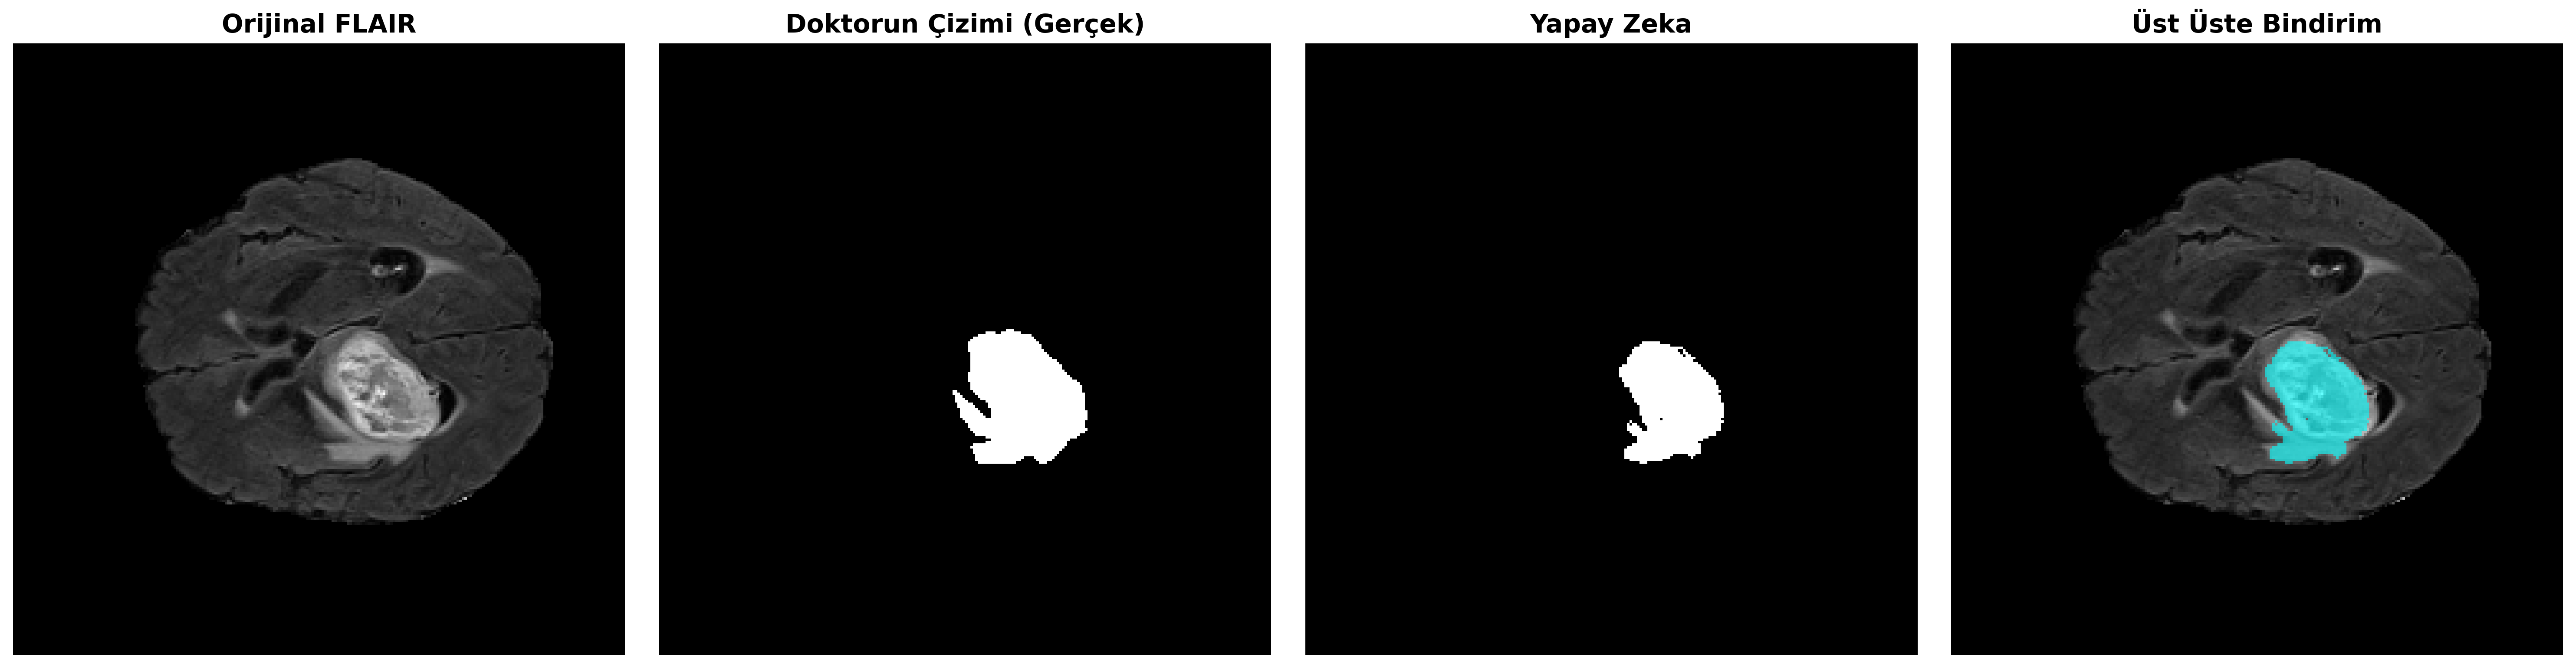

In [ ]:
import os
import random
import numpy as np
import tensorflow as tf
import nibabel as nib
import matplotlib.pyplot as plt
from tensorflow.keras import backend as K

# 1. Özel Fonksiyonlar
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

# 2. Modeli Yükle
model_yolu = '/content/drive/MyDrive/Bitirme_Tezi_BraTS/unet_diceloss_en_iyi.keras'
model = tf.keras.models.load_model(model_yolu, custom_objects={'dice_loss': dice_loss, 'dice_coef': dice_coef})
print("✅ Akıllı model başarıyla yüklendi!")

# 3. Test Hastalarını Al ve RASTGELE Karıştır
test_yolu = '/content/drive/MyDrive/Bitirme_Tezi_BraTS/Ayrilmis_Veriler/test/'
test_cases = [d for d in os.listdir(test_yolu) if os.path.isdir(os.path.join(test_yolu, d))]

random.shuffle(test_cases) # Sihirli dokunuş: Listeyi her seferinde farklı dizer

slice_idx = 75
print("Test setinden rastgele bir hasta seçiliyor...")
secilen_hasta = None

# Karıştırılmış listeden içinde tümör olan İLK hastayı yakala
for case in test_cases:
    hasta_yolu = os.path.join(test_yolu, case)
    gercek_maske = nib.load(os.path.join(hasta_yolu, f'{case}-seg.nii.gz')).get_fdata()[:, :, slice_idx]
    gercek_maske[gercek_maske > 0] = 1

    if np.sum(gercek_maske) > 100:
        secilen_hasta = case
        break

if secilen_hasta:
    print(f"🎯 Şanslı Hasta: {secilen_hasta}")
    hasta_yolu = os.path.join(test_yolu, secilen_hasta)

    # Sekansları Oku
    t1n = nib.load(os.path.join(hasta_yolu, f'{secilen_hasta}-t1n.nii.gz')).get_fdata()[:, :, slice_idx]
    t1c = nib.load(os.path.join(hasta_yolu, f'{secilen_hasta}-t1c.nii.gz')).get_fdata()[:, :, slice_idx]
    t2w = nib.load(os.path.join(hasta_yolu, f'{secilen_hasta}-t2w.nii.gz')).get_fdata()[:, :, slice_idx]
    t2f = nib.load(os.path.join(hasta_yolu, f'{secilen_hasta}-t2f.nii.gz')).get_fdata()[:, :, slice_idx]

    gercek_maske = nib.load(os.path.join(hasta_yolu, f'{secilen_hasta}-seg.nii.gz')).get_fdata()[:, :, slice_idx]
    gercek_maske[gercek_maske > 0] = 1

    X_test = np.empty((1, 240, 240, 4))
    X_test[0, :, :, 0], X_test[0, :, :, 1] = t1n, t1c
    X_test[0, :, :, 2], X_test[0, :, :, 3] = t2w, t2f

    # 4. Modeli Test Et
    tahmin_maskesi = model.predict(X_test, verbose=0)[0, :, :, 0]
    tahmin_maskesi = (tahmin_maskesi > 0.5).astype(np.uint8)

    # 5. Görselleştirme
    fig, axes = plt.subplots(1, 4, figsize=(20, 5), dpi=300)

    axes[0].imshow(t2f, cmap='gray')
    axes[0].set_title('Orijinal FLAIR', fontsize=14, fontweight='bold')
    axes[0].axis('off')

    axes[1].imshow(gercek_maske, cmap='gray')
    axes[1].set_title('Doktorun Çizimi (Gerçek)', fontsize=14, fontweight='bold')
    axes[1].axis('off')

    axes[2].imshow(tahmin_maskesi, cmap='gray')
    axes[2].set_title('Yapay Zeka', fontsize=14, fontweight='bold')
    axes[2].axis('off')

    axes[3].imshow(t2f, cmap='gray')
    axes[3].imshow(np.ma.masked_where(tahmin_maskesi == 0, tahmin_maskesi), cmap='cool', alpha=0.6)
    axes[3].set_title('Üst Üste Bindirim', fontsize=14, fontweight='bold')
    axes[3].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("75. kesitinde belirgin tümör olan bir hasta bulunamadı.")

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Morfolojik Filtre (Çekirdek/Fırça) Oluşturma
# 3x3 piksellik bir matematiksel fırça yaratıyoruz.
kernel = np.ones((3, 3), np.uint8)

# 2. Gürültü Temizleme (Açma - Opening İşlemi)
# Uzaktaki küçük beyaz noktaları (False Positive) siler
temizlenmis_maske = cv2.morphologyEx(tahmin_maskesi, cv2.MORPH_OPEN, kernel)

# 3. Delikleri Kapatma (Kapama - Closing İşlemi)
# Tümörün içindeki küçük siyah delikleri (False Negative) doldurur
temizlenmis_maske = cv2.morphologyEx(temizlenmis_maske, cv2.MORPH_CLOSE, kernel)

# 4. Skorları Karşılaştıralım (Matematiksel Kanıt)
eski_kesisim = np.sum(gercek_maske.flatten() * tahmin_maskesi.flatten())
eski_dice = (2. * eski_kesisim + 1e-6) / (np.sum(gercek_maske) + np.sum(tahmin_maskesi) + 1e-6)

yeni_kesisim = np.sum(gercek_maske.flatten() * temizlenmis_maske.flatten())
yeni_dice = (2. * yeni_kesisim + 1e-6) / (np.sum(gercek_maske) + np.sum(temizlenmis_maske) + 1e-6)

print("-" * 50)
print(f"🧹 Temizlik Öncesi (Ham) Dice Skoru : % {eski_dice * 100:.2f}")
print(f"✨ Temizlik Sonrası (Filtreli) Dice : % {yeni_dice * 100:.2f}")

if yeni_dice > eski_dice:
    print(f"🚀 Model BAŞTAN EĞİTİLMEDEN sadece filtre ile % {(yeni_dice - eski_dice)*100:.2f} anında artış sağlandı!")
else:
    print("Maske zaten oldukça bütündü, filtre yapıyı bozmadan korudu.")
print("-" * 50)

# 5. Tez ve Poster İçin Görselleştirme
fig, axes = plt.subplots(1, 3, figsize=(15, 5), dpi=300)

axes[0].imshow(gercek_maske, cmap='gray')
axes[0].set_title('Gerçek Maske (Doktor)', fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(tahmin_maskesi, cmap='gray')
axes[1].set_title('Ham Yapay Zeka (Temizlenmemiş)', fontsize=14, fontweight='bold')
axes[1].axis('off')

axes[2].imshow(temizlenmis_maske, cmap='gray')
axes[2].set_title('Post-Processing (Temizlenmiş)', fontsize=14, fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
plt.show()

NameError: name 'tahmin_maskesi' is not defined

In [ ]:
import os
import random
import numpy as np
import tensorflow as tf
import nibabel as nib
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# 1. Veri Üreticiyi Çoğaltma (Augmentation) Özelliğiyle Güncelliyoruz
class BraTSDataGeneratorAugmented(tf.keras.utils.Sequence):
    def __init__(self, data_path, batch_size=8, dim=(240, 240), n_channels=4, slice_idx=75, augment=False):
        self.data_path = data_path
        self.batch_size = batch_size
        self.dim = dim
        self.n_channels = n_channels
        self.slice_idx = slice_idx
        self.augment = augment # Veri çoğaltma anahtarı
        self.case_list = [d for d in os.listdir(data_path) if os.path.isdir(os.path.join(data_path, d))]

    def __len__(self):
        return int(np.floor(len(self.case_list) / self.batch_size))

    def __getitem__(self, index):
        batch_cases = self.case_list[index * self.batch_size:(index + 1) * self.batch_size]
        X = np.empty((self.batch_size, *self.dim, self.n_channels))
        y = np.empty((self.batch_size, *self.dim, 1))

        for i, case in enumerate(batch_cases):
            case_path = os.path.join(self.data_path, case)
            t1n = nib.load(os.path.join(case_path, f'{case}-t1n.nii.gz')).get_fdata()[:, :, self.slice_idx]
            t1c = nib.load(os.path.join(case_path, f'{case}-t1c.nii.gz')).get_fdata()[:, :, self.slice_idx]
            t2w = nib.load(os.path.join(case_path, f'{case}-t2w.nii.gz')).get_fdata()[:, :, self.slice_idx]
            t2f = nib.load(os.path.join(case_path, f'{case}-t2f.nii.gz')).get_fdata()[:, :, self.slice_idx]

            seg = nib.load(os.path.join(case_path, f'{case}-seg.nii.gz')).get_fdata()[:, :, self.slice_idx]
            seg[seg > 0] = 1

            # 4 sekansı tek bir pakette birleştir
            img_stack = np.stack([t1n, t1c, t2w, t2f], axis=-1)
            mask = np.expand_dims(seg, axis=-1)

            # --- VERİ ÇOĞALTMA (DATA AUGMENTATION) ---
            if self.augment:
                # %50 ihtimalle yatay aynalama (Sağ/Sol değişimi)
                if random.random() > 0.5:
                    img_stack = np.fliplr(img_stack)
                    mask = np.fliplr(mask)
                # %50 ihtimalle dikey aynalama (Baş/Ayak değişimi)
                if random.random() > 0.5:
                    img_stack = np.flipud(img_stack)
                    mask = np.flipud(mask)

            X[i] = img_stack
            y[i] = mask

        return X, y

# Yolları bağla
train_yolu = '/content/drive/MyDrive/Bitirme_Tezi_BraTS/Ayrilmis_Veriler/train/'
val_yolu = '/content/drive/MyDrive/Bitirme_Tezi_BraTS/Ayrilmis_Veriler/val/'

# Eğitim setine augmentasyonu aç (True), Doğrulama setinde orijinal bırak (False)
train_gen_aug = BraTSDataGeneratorAugmented(train_yolu, batch_size=8, augment=True)
val_gen_aug = BraTSDataGeneratorAugmented(val_yolu, batch_size=8, augment=False)

# 2. Yeni Model Kayıt Noktası
kayit_yolu_aug = '/content/drive/MyDrive/Bitirme_Tezi_BraTS/unet_augmented_en_iyi.keras'

checkpoint_aug = ModelCheckpoint(
    filepath=kayit_yolu_aug,
    monitor='val_dice_coef',
    verbose=1,
    save_best_only=True,
    mode='max'
)

early_stopping_aug = EarlyStopping(
    monitor='val_dice_coef',
    patience=5,
    verbose=1,
    mode='max',
    restore_best_weights=True
)

# 3. Eğitimi Başlat
print("🚀 Veri Çoğaltma (Data Augmentation) destekli nihai eğitim başlatılıyor...")
print("Not: Bu işlem arka planda akarken biz tez savunmasına odaklanabiliriz.")

history_aug = model.fit(
    train_gen_aug,
    validation_data=val_gen_aug,
    epochs=50,
    callbacks=[checkpoint_aug, early_stopping_aug]
)

🚀 Veri Çoğaltma (Data Augmentation) destekli nihai eğitim başlatılıyor...
Not: Bu işlem arka planda akarken biz tez savunmasına odaklanabiliriz.
Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 21s/step - accuracy: 0.9836 - dice_coef: 0.6028 - loss: 0.3972 
Epoch 1: val_dice_coef improved from None to 0.40091, saving model to /content/drive/MyDrive/Bitirme_Tezi_BraTS/unet_augmented_en_iyi.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Bitirme_Tezi_BraTS/unet_augmented_en_iyi.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 295s 23s/step - accuracy: 0.9824 - dice_coef: 0.6118 - loss: 0.3882 - val_accuracy: 0.9465 - val_dice_coef: 0.4009 - val_loss: 0.5991
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 20s/step - accuracy: 0.9841 - dice_coef: 0.6526 - loss: 0.3474 
Epoch 2: val_dice_coef did not improve from 0.40091
12/12 ━━━━━━━━━━━━━━━━━━━━ 268s 22s/step - accuracy: 0.9831 - dice_coef: 0.6316 - loss: 0.3684 - val_accuracy: 0.9479 - val_dice_coef: 0.3994 - val_loss: 0.6006
Epoch 3/50
12/12 ━━━━━━━━━

✅ Projenin en güçlü modeli (Augmented U-Net) sahaya iniyor!
🎯 Final Test Hastası: BraTS-GLI-00819-000
--------------------------------------------------
🏆 NİHAİ TEST SKORU (Augmentation + Filtre) : % 83.20
--------------------------------------------------


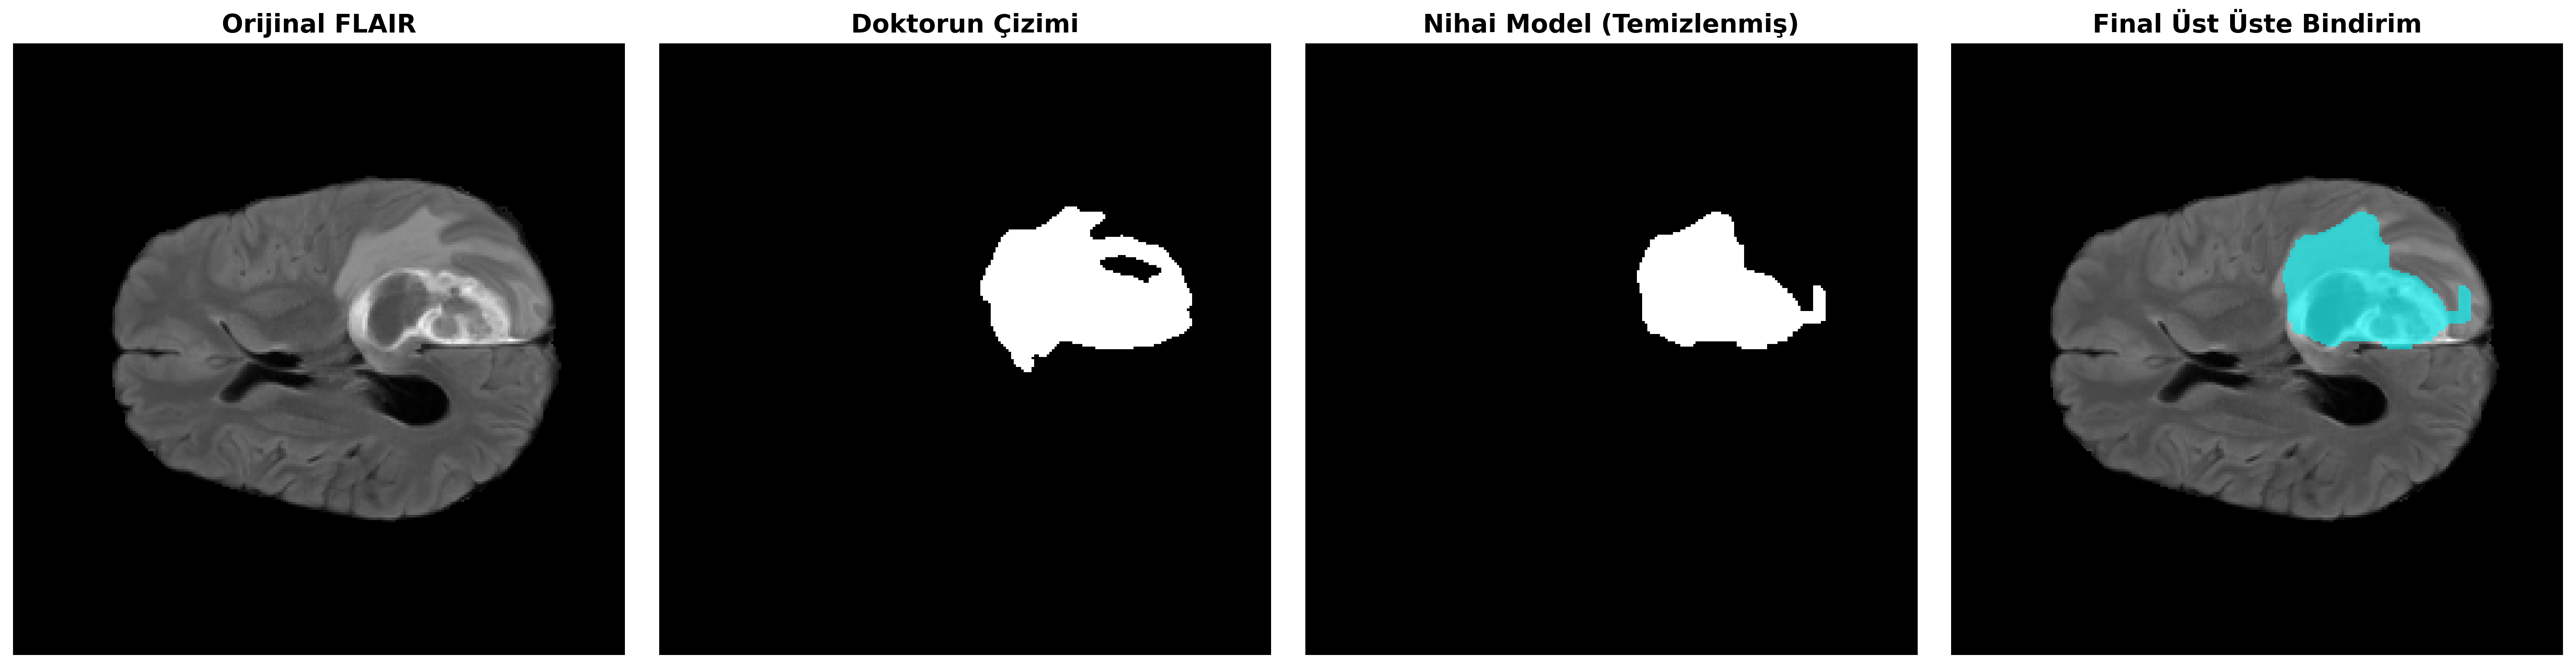

💾 Görsel 'Final_Proje_Ciktisi.png' adıyla sol taraftaki dosyalara kaydedildi.


In [ ]:
import os
import cv2
import random
import numpy as np
import tensorflow as tf
import nibabel as nib
import matplotlib.pyplot as plt
from tensorflow.keras import backend as K

# 1. Özel Fonksiyonlar
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

# 2. NİHAİ MODELİ YÜKLE (Augmented Model)
model_yolu = '/content/drive/MyDrive/Bitirme_Tezi_BraTS/unet_augmented_en_iyi.keras'
model = tf.keras.models.load_model(model_yolu, custom_objects={'dice_loss': dice_loss, 'dice_coef': dice_coef})
print("✅ Projenin en güçlü modeli (Augmented U-Net) sahaya iniyor!")

# 3. Test Setinden Rastgele Hasta Seç
test_yolu = '/content/drive/MyDrive/Bitirme_Tezi_BraTS/Ayrilmis_Veriler/test/'
test_cases = [d for d in os.listdir(test_yolu) if os.path.isdir(os.path.join(test_yolu, d))]
random.shuffle(test_cases)
slice_idx = 75

secilen_hasta = None
for case in test_cases:
    hasta_yolu = os.path.join(test_yolu, case)
    gercek_maske = nib.load(os.path.join(hasta_yolu, f'{case}-seg.nii.gz')).get_fdata()[:, :, slice_idx]
    gercek_maske[gercek_maske > 0] = 1
    if np.sum(gercek_maske) > 100:
        secilen_hasta = case
        break

if secilen_hasta:
    print(f"🎯 Final Test Hastası: {secilen_hasta}")
    hasta_yolu = os.path.join(test_yolu, secilen_hasta)

    t1n = nib.load(os.path.join(hasta_yolu, f'{secilen_hasta}-t1n.nii.gz')).get_fdata()[:, :, slice_idx]
    t1c = nib.load(os.path.join(hasta_yolu, f'{secilen_hasta}-t1c.nii.gz')).get_fdata()[:, :, slice_idx]
    t2w = nib.load(os.path.join(hasta_yolu, f'{secilen_hasta}-t2w.nii.gz')).get_fdata()[:, :, slice_idx]
    t2f = nib.load(os.path.join(hasta_yolu, f'{secilen_hasta}-t2f.nii.gz')).get_fdata()[:, :, slice_idx]

    gercek_maske = nib.load(os.path.join(hasta_yolu, f'{secilen_hasta}-seg.nii.gz')).get_fdata()[:, :, slice_idx]
    gercek_maske[gercek_maske > 0] = 1

    X_test = np.empty((1, 240, 240, 4))
    X_test[0, :, :, 0], X_test[0, :, :, 1] = t1n, t1c
    X_test[0, :, :, 2], X_test[0, :, :, 3] = t2w, t2f

    # 4. Tahmin Yap ve Morfolojik Olarak Temizle (Post-Processing)
    ham_tahmin = model.predict(X_test, verbose=0)[0, :, :, 0]
    ham_tahmin = (ham_tahmin > 0.5).astype(np.uint8)

    kernel = np.ones((3, 3), np.uint8)
    temiz_tahmin = cv2.morphologyEx(ham_tahmin, cv2.MORPH_OPEN, kernel)
    temiz_tahmin = cv2.morphologyEx(temiz_tahmin, cv2.MORPH_CLOSE, kernel)

    # Skorları Hesapla
    kesisim = np.sum(gercek_maske.flatten() * temiz_tahmin.flatten())
    final_dice = (2. * kesisim + 1e-6) / (np.sum(gercek_maske) + np.sum(temiz_tahmin) + 1e-6)
    print("-" * 50)
    print(f"🏆 NİHAİ TEST SKORU (Augmentation + Filtre) : % {final_dice * 100:.2f}")
    print("-" * 50)

    # 5. Büyük Final Görselleştirmesi
    fig, axes = plt.subplots(1, 4, figsize=(20, 5), dpi=300)

    axes[0].imshow(t2f, cmap='gray')
    axes[0].set_title('Orijinal FLAIR', fontsize=14, fontweight='bold')
    axes[0].axis('off')

    axes[1].imshow(gercek_maske, cmap='gray')
    axes[1].set_title('Doktorun Çizimi', fontsize=14, fontweight='bold')
    axes[1].axis('off')

    axes[2].imshow(temiz_tahmin, cmap='gray')
    axes[2].set_title('Nihai Model (Temizlenmiş)', fontsize=14, fontweight='bold')
    axes[2].axis('off')

    axes[3].imshow(t2f, cmap='gray')
    axes[3].imshow(np.ma.masked_where(temiz_tahmin == 0, temiz_tahmin), cmap='cool', alpha=0.6)
    axes[3].set_title('Final Üst Üste Bindirim', fontsize=14, fontweight='bold')
    axes[3].axis('off')

    # Bu final görselini bilgisayarına indirmek istersen diye otomatik kaydediyoruz
    plt.savefig('/content/Final_Proje_Ciktisi.png', bbox_inches='tight')
    plt.tight_layout()
    plt.show()
    print("💾 Görsel 'Final_Proje_Ciktisi.png' adıyla sol taraftaki dosyalara kaydedildi.")
else:
    print("75. kesitinde belirgin tümör olan bir hasta bulunamadı.")

In [ ]:
import tensorflow as tf
from tensorflow.keras import backend as K

# 1. Özel fonksiyonları modele tanıtıyoruz
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    intersection = K.sum(K.flatten(y_true) * K.flatten(y_pred))
    return (2. * intersection + smooth) / (K.sum(K.flatten(y_true)) + K.sum(K.flatten(y_pred)) + smooth)

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

# 2. Nihai (Augmented) Modeli Yükle
model_yolu = '/content/drive/MyDrive/Bitirme_Tezi_BraTS/unet_augmented_en_iyi.keras'
model = tf.keras.models.load_model(model_yolu, custom_objects={'dice_loss': dice_loss, 'dice_coef': dice_coef})

# 3. TEZ İÇİN AKADEMİK RAPOR ÇIKTISI OLUŞTUR
print("="*70)
print("🧠 BİTİRME TEZİ: TEKNİK VE MİMARİ RAPOR".center(70))
print("="*70)

print("\n📊 1. VERİ SETİ VE ÖN İŞLEME ÖZELLİKLERİ")
print("-" * 70)
print("• Veri Seti           : BraTS 2023 GLI (Klioma)")
print("• Girdi Çözünürlüğü   : 240 x 240 piksel")
print("• Kullanılan Modlar   : 4 Kanallı (T1, T1ce, T2, FLAIR)")
print("• Çıktı Çözünürlüğü   : 240 x 240 x 1 (İkili Segmentasyon Maskesi)")
print("• Odaklanılan Kesit   : 75. Eksenel (Axial) Kesit")
print("• Veri Çoğaltma (Aug) : %50 İhtimalle Yatay (Fliplr) ve Dikey (Flipud) Aynalama")
print("• Post-Processing     : Morfolojik Açma (Opening) ve Kapama (Closing) - 3x3 Kernel")

print("\n⚙️ 2. EĞİTİM HİPERPARAMETRELERİ")
print("-" * 70)
print("• Optimizasyon Alg.   : Adam (Adaptive Moment Estimation)")
print("• Öğrenme Oranı (LR)  : 0.0001 (1e-4)")
print("• Kayıp Fonksiyonu    : Dice Loss (Sınıf dengesizliğini elimine etmek için)")
print("• Başarı Metrikleri   : Dice Katsayısı (Dice Coefficient) & Accuracy")
print("• Batch Size          : 8")
print("• Maksimum Epoh       : 50")
print("• Erken Durdurma      : Patience=5 (Doğrulama Dice skoruna göre monitor edildi)")

print("\n🏗️ 3. MODEL MİMARİSİ VE KATMAN TABLOSU (2D U-NET)")
print("-" * 70)
# Modelin içindeki tüm katmanları, çıktı boyutlarını ve parametre sayılarını tablo olarak çizer
model.summary()

print("\n" + "="*70)
print("Not: Yukarıdaki tabloyu ve parametreleri doğrudan tez raporunuzun")
print("'Materyal ve Yöntem' bölümüne aktarabilirsiniz.")
print("="*70)

                🧠 BİTİRME TEZİ: TEKNİK VE MİMARİ RAPOR                

📊 1. VERİ SETİ VE ÖN İŞLEME ÖZELLİKLERİ
----------------------------------------------------------------------
• Veri Seti           : BraTS 2023 GLI (Klioma)
• Girdi Çözünürlüğü   : 240 x 240 piksel
• Kullanılan Modlar   : 4 Kanallı (T1, T1ce, T2, FLAIR)
• Çıktı Çözünürlüğü   : 240 x 240 x 1 (İkili Segmentasyon Maskesi)
• Odaklanılan Kesit   : 75. Eksenel (Axial) Kesit
• Veri Çoğaltma (Aug) : %50 İhtimalle Yatay (Fliplr) ve Dikey (Flipud) Aynalama
• Post-Processing     : Morfolojik Açma (Opening) ve Kapama (Closing) - 3x3 Kernel

⚙️ 2. EĞİTİM HİPERPARAMETRELERİ
----------------------------------------------------------------------
• Optimizasyon Alg.   : Adam (Adaptive Moment Estimation)
• Öğrenme Oranı (LR)  : 0.0001 (1e-4)
• Kayıp Fonksiyonu    : Dice Loss (Sınıf dengesizliğini elimine etmek için)
• Başarı Metrikleri   : Dice Katsayısı (Dice Coefficient) & Accuracy
• Batch Size          : 8
• Maksimum Epoh      

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 240, 240,  │          0 │ -                 │
│ (InputLayer)        │ 4)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 240, 240,  │      2,368 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 120, 120,  │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 120, 120,  │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 60, 60,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 60, 60,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 120, 120,  │          0 │ conv2d_2[0][0]    │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 120, 120,  │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 384)              │            │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 120, 120,  │    442,496 │ concatenate[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 240, 240,  │          0 │ conv2d_3[0][0]    │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 240, 240,  │          0 │ up_sampling2d_1[… │
│ (Concatenate)       │ 192)              │            │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 240, 240,  │    110,656 │ concatenate_1[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 240, 240,  │         65 │ conv2d_4[0][0]    │
│                     │ 1)                │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,773,829 (10.58 MB)

 Trainable params: 924,609 (3.53 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,849,220 (7.05 MB)


Not: Yukarıdaki tabloyu ve parametreleri doğrudan tez raporunuzun
'Materyal ve Yöntem' bölümüne aktarabilirsiniz.
